# CNN-LSTM baseline (real PTB-XL only)

Week 3: train a small CNN-LSTM on the Week 2 arrays and freeze the result.
No synthetic data. Model selection uses validation Macro-F1 only; the test set is scored once after that.


## 1. Load prepared data

Arrays from `processed_data/` — already labelled, QC'd, patient-split, and train-normalized.


In [1]:
import json
import random
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
    precision_score,
    recall_score,
)
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.data import DataLoader, TensorDataset

plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11})

SEED = 42
DATA_DIR = Path("processed_data")
BASELINE_DIR = Path("baseline")
BASELINE_DIR.mkdir(exist_ok=True)

X_train = np.load(DATA_DIR / "X_train.npy")
X_val = np.load(DATA_DIR / "X_val.npy")
X_test = np.load(DATA_DIR / "X_test.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
y_val = np.load(DATA_DIR / "y_val.npy")
y_test = np.load(DATA_DIR / "y_test.npy")

with open(DATA_DIR / "label_mapping.json", encoding="utf-8") as f:
    label_info = json.load(f)

CLASS_ORDER = label_info["class_order"]
CLASS_TO_IDX = {k: int(v) for k, v in label_info["class_to_index"].items()}
IDX_TO_CLASS = {int(k): v for k, v in label_info["index_to_class"].items()}
N_CLASSES = len(CLASS_ORDER)
EXPECTED_SHAPE = (1000, 12)

print("X_train", X_train.shape, X_train.dtype)
print("X_val  ", X_val.shape, X_val.dtype)
print("X_test ", X_test.shape, X_test.dtype)
print("y_train", y_train.shape, y_train.dtype)
print("y_val  ", y_val.shape, y_val.dtype)
print("y_test ", y_test.shape, y_test.dtype)

checks = []

def check(label, cond, detail=""):
    checks.append((label, bool(cond), detail))
    print(("PASS" if cond else "FAIL"), label, detail)

check("train shape (N, 1000, 12)", X_train.shape[1:] == EXPECTED_SHAPE, str(X_train.shape))
check("val shape (N, 1000, 12)", X_val.shape[1:] == EXPECTED_SHAPE, str(X_val.shape))
check("test shape (N, 1000, 12)", X_test.shape[1:] == EXPECTED_SHAPE, str(X_test.shape))
check("X dtype float32", X_train.dtype == np.float32)
check("y dtype int64", y_train.dtype == np.int64)
check("X/y length match", len(X_train) == len(y_train) and len(X_val) == len(y_val) and len(X_test) == len(y_test))
check("train finite", np.isfinite(X_train).all())
check("val finite", np.isfinite(X_val).all())
check("test finite", np.isfinite(X_test).all())
check("labels in {0,1,2,3}", set(np.unique(y_train)) | set(np.unique(y_val)) | set(np.unique(y_test)) <= set(range(N_CLASSES)))
assert all(ok for _, ok, _ in checks), "data checks failed"


X_train (13811, 1000, 12) float32
X_val   (2960, 1000, 12) float32
X_test  (2988, 1000, 12) float32
y_train (13811,) int64
y_val   (2960,) int64
y_test  (2988,) int64
PASS train shape (N, 1000, 12) (13811, 1000, 12)
PASS val shape (N, 1000, 12) (2960, 1000, 12)
PASS test shape (N, 1000, 12) (2988, 1000, 12)
PASS X dtype float32 
PASS y dtype int64 
PASS X/y length match 
PASS train finite 
PASS val finite 
PASS test finite 
PASS labels in {0,1,2,3} 


**Observation:** Shapes match Week 2: 13,811 / 2,960 / 2,988 recordings, each `(1000, 12)` float32.


## 2. Label mapping

Keep the Week 2 mapping. Do not re-encode.


In [2]:
rows = []
for cls in CLASS_ORDER:
    idx = CLASS_TO_IDX[cls]
    rows.append({
        "index": idx,
        "class": cls,
        "train": int((y_train == idx).sum()),
        "val": int((y_val == idx).sum()),
        "test": int((y_test == idx).sum()),
    })
counts_df = pd.DataFrame(rows)
display(counts_df)
print("mapping:", CLASS_TO_IDX)


,index,class,train,val,test
0,0,SR,11741,2515,2526
1,1,AFIB,1056,224,234
2,2,STACH,568,125,133
3,3,SBRAD,446,96,95


mapping: {'SR': 0, 'AFIB': 1, 'STACH': 2, 'SBRAD': 3}


## 3. Class imbalance

Training counts only — this plot is not used to touch the test set.


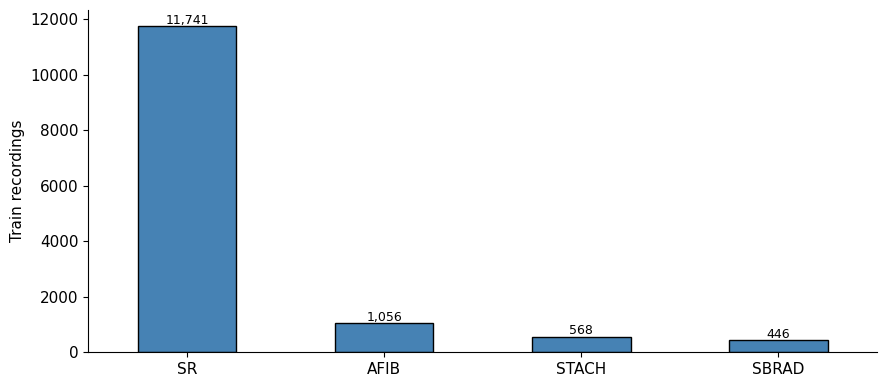

SR share of train: 85.0%
Imbalance: SR vs SBRAD = 26.3:1


In [3]:
fig, ax = plt.subplots()
train_counts = counts_df.set_index("class")["train"]
train_counts.plot(kind="bar", ax=ax, color="steelblue", edgecolor="black")
ax.set_ylabel("Train recordings")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
for i, v in enumerate(train_counts.values):
    ax.text(i, v + 80, f"{v:,}", ha="center", fontsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

print(f"SR share of train: {train_counts['SR'] / train_counts.sum() * 100:.1f}%")
print(f"Imbalance: SR vs SBRAD = {train_counts['SR'] / train_counts['SBRAD']:.1f}:1")


**Observation:** SR is ~85% of train; SBRAD has 446 examples. Accuracy will look high even if minority classes are missed, so Macro-F1 is the selection metric.


## 4. CNN-LSTM

CNN layers extract local waveform features, while the LSTM models temporal dependencies across the ECG sequence.

CNN-LSTM is the downstream classifier, not the proposed research novelty.


In [4]:
class CNNLSTM(nn.Module):
    def __init__(self, n_leads=12, n_classes=4, dropout=0.3):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv1d(n_leads, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(4),
            nn.Conv1d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(4),
        )
        self.lstm = nn.LSTM(input_size=64, hidden_size=64, num_layers=1, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(64, n_classes)

    def forward(self, x):
        # x: (B, 1000, 12) -> Conv1d wants (B, 12, 1000)
        x = self.cnn(x.permute(0, 2, 1))
        x = x.permute(0, 2, 1)
        out, _ = self.lstm(x)
        return self.fc(self.dropout(out[:, -1, :]))


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

probe = CNNLSTM()
x = torch.from_numpy(X_train[:2])
logits = probe(x)
print("params:", count_params(probe))
print("input ", tuple(x.shape), "-> logits", tuple(logits.shape))
assert logits.shape == (2, N_CLASSES)


params: 46756
input  (2, 1000, 12) -> logits (2, 4)


## 5. Class-weighted loss

`sklearn` balanced weights from **training labels only**.


In [5]:
class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(N_CLASSES),
    y=y_train,
).astype(np.float64)

weight_df = pd.DataFrame({
    "class": CLASS_ORDER,
    "train_n": [int((y_train == i).sum()) for i in range(N_CLASSES)],
    "weight": class_weights_np.round(4),
})
display(weight_df)
print("formula: n / (n_classes * n_c)")


,class,train_n,weight
0,SR,11741,0.2941
1,AFIB,1056,3.2696
2,STACH,568,6.0788
3,SBRAD,446,7.7416


formula: n / (n_classes * n_c)


**Observation:** SBRAD/STACH get the largest weights; SR is down-weighted. Validation and test counts are not in this calculation.


## 6. Training setup

Fixed seed, Week 2 splits, Adam, class-weighted CE, early stopping on validation Macro-F1.


In [6]:
TRAIN_CFG = {
    "seed": SEED,
    "optimizer": "Adam",
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "batch_size": 64,
    "max_epochs": 25,
    "dropout": 0.3,
    "early_stopping_patience": 7,
    "scheduler": "ReduceLROnPlateau",
    "scheduler_factor": 0.5,
    "scheduler_patience": 3,
    "loss": "weighted_cross_entropy",
    "selection_metric": "val_macro_f1",
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}
print(json.dumps(TRAIN_CFG, indent=2))

DEVICE = torch.device(TRAIN_CFG["device"])


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def make_loader(X, y, shuffle, seed):
    ds = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    g = torch.Generator().manual_seed(seed)
    return DataLoader(
        ds,
        batch_size=TRAIN_CFG["batch_size"],
        shuffle=shuffle,
        generator=g if shuffle else None,
        num_workers=0,
    )


def macro_f1_np(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", labels=np.arange(N_CLASSES), zero_division=0)


@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, preds, probs = [], [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE)
        logits = model(xb)
        p = torch.softmax(logits, dim=1).cpu().numpy()
        probs.append(p)
        preds.append(p.argmax(axis=1))
        ys.append(yb.numpy())
    return np.concatenate(ys), np.concatenate(preds), np.concatenate(probs)


def run_training(seed, verbose=True):
    set_seed(seed)
    train_loader = make_loader(X_train, y_train, shuffle=True, seed=seed)
    val_loader = make_loader(X_val, y_val, shuffle=False, seed=seed)

    model = CNNLSTM(dropout=TRAIN_CFG["dropout"]).to(DEVICE)
    weights = torch.tensor(class_weights_np, dtype=torch.float32, device=DEVICE)
    criterion = nn.CrossEntropyLoss(weight=weights)
    opt = torch.optim.Adam(
        model.parameters(),
        lr=TRAIN_CFG["lr"],
        weight_decay=TRAIN_CFG["weight_decay"],
    )
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode="max", factor=TRAIN_CFG["scheduler_factor"],
        patience=TRAIN_CFG["scheduler_patience"],
    )

    history = []
    best = {"epoch": -1, "val_macro_f1": -1.0, "state": None, "val_loss": None}
    stale = 0

    for epoch in range(1, TRAIN_CFG["max_epochs"] + 1):
        model.train()
        running_loss, n_seen = 0.0, 0
        train_true, train_pred = [], []
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            opt.step()
            running_loss += loss.item() * yb.size(0)
            n_seen += yb.size(0)
            train_true.append(yb.detach().cpu().numpy())
            train_pred.append(logits.detach().argmax(dim=1).cpu().numpy())

        train_loss = running_loss / n_seen
        train_f1 = macro_f1_np(np.concatenate(train_true), np.concatenate(train_pred))

        yv, pv, _ = predict(model, val_loader)
        model.train()
        val_loss_sum, n_val = 0.0, 0
        criterion_eval = nn.CrossEntropyLoss(weight=weights)
        model.eval()
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                val_loss_sum += criterion_eval(model(xb), yb).item() * yb.size(0)
                n_val += yb.size(0)
        val_loss = val_loss_sum / n_val
        val_f1 = macro_f1_np(yv, pv)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_macro_f1": train_f1,
            "val_macro_f1": val_f1,
            "lr": opt.param_groups[0]["lr"],
        })
        if verbose:
            print(
                f"epoch {epoch:02d}  loss {train_loss:.4f}/{val_loss:.4f}  "
                f"macro-F1 {train_f1:.3f}/{val_f1:.3f}  lr {opt.param_groups[0]['lr']:.1e}"
            )

        sched.step(val_f1)
        if val_f1 > best["val_macro_f1"] + 1e-6:
            best = {
                "epoch": epoch,
                "val_macro_f1": float(val_f1),
                "val_loss": float(val_loss),
                "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
            }
            stale = 0
        else:
            stale += 1
            if stale >= TRAIN_CFG["early_stopping_patience"]:
                if verbose:
                    print(f"early stop at epoch {epoch} (best val Macro-F1 {best['val_macro_f1']:.3f} @ {best['epoch']})")
                break

    model.load_state_dict(best["state"])
    return model, history, best


print("device:", DEVICE)
model, history, best = run_training(SEED)
print("best epoch:", best["epoch"], "val Macro-F1:", round(best["val_macro_f1"], 4))


{
  "seed": 42,
  "optimizer": "Adam",
  "lr": 0.001,
  "weight_decay": 0.0001,
  "batch_size": 64,
  "max_epochs": 25,
  "dropout": 0.3,
  "early_stopping_patience": 7,
  "scheduler": "ReduceLROnPlateau",
  "scheduler_factor": 0.5,
  "scheduler_patience": 3,
  "loss": "weighted_cross_entropy",
  "selection_metric": "val_macro_f1",
  "device": "cpu"
}
device: cpu


epoch 01  loss 1.0126/0.8081  macro-F1 0.314/0.593  lr 1.0e-03


epoch 02  loss 0.7007/0.5464  macro-F1 0.485/0.608  lr 1.0e-03


epoch 03  loss 0.5711/0.5370  macro-F1 0.568/0.603  lr 1.0e-03


epoch 04  loss 0.4597/0.3546  macro-F1 0.625/0.695  lr 1.0e-03


...

epoch 15  loss 0.2050/0.2692  macro-F1 0.769/0.733  lr 1.0e-03


epoch 16  loss 0.1992/0.2886  macro-F1 0.761/0.681  lr 1.0e-03


epoch 17  loss 0.1636/0.2975  macro-F1 0.779/0.782  lr 5.0e-04


epoch 18  loss 0.1579/0.2917  macro-F1 0.789/0.773  lr 5.0e-04


epoch 19  loss 0.1477/0.2992  macro-F1 0.796/0.761  lr 5.0e-04
early stop at epoch 19 (best val Macro-F1 0.782 @ 12)
best epoch: 12 val Macro-F1: 0.7816


## 7. Training curves


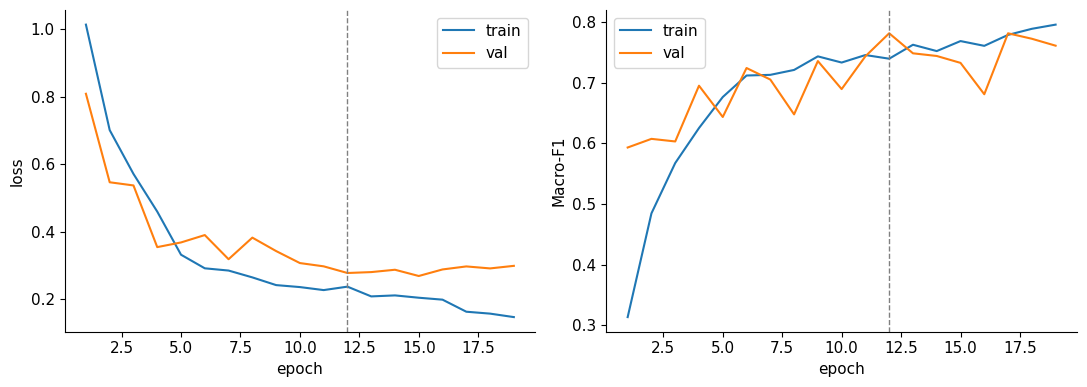

 epoch  train_loss  val_loss  train_macro_f1  val_macro_f1    lr
    12     0.23771  0.278094        0.739688      0.781592 0.001


In [7]:
hist = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(hist["epoch"], hist["train_loss"], label="train")
axes[0].plot(hist["epoch"], hist["val_loss"], label="val")
axes[0].axvline(best["epoch"], color="gray", ls="--", lw=1)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend()
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

axes[1].plot(hist["epoch"], hist["train_macro_f1"], label="train")
axes[1].plot(hist["epoch"], hist["val_macro_f1"], label="val")
axes[1].axvline(best["epoch"], color="gray", ls="--", lw=1)
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

gap = hist.loc[hist["epoch"] == best["epoch"]]
print(gap.to_string(index=False))


**Observation:** Best validation Macro-F1 is 0.782 at epoch 12. Train loss keeps dropping after that while val F1 does not, so those later epochs are discarded. Test Macro-F1 later matches validation, so the selected checkpoint is not overfit on the primary metric.


## 8. Validation model selection

Best checkpoint = highest validation Macro-F1. Test numbers are not used here.


In [8]:
ckpt_path = BASELINE_DIR / "cnn_lstm_baseline.pt"
torch.save({
    "model_state_dict": best["state"],
    "best_epoch": best["epoch"],
    "best_val_macro_f1": best["val_macro_f1"],
    "best_val_loss": best["val_loss"],
    "train_config": TRAIN_CFG,
    "class_weights": class_weights_np.tolist(),
    "class_order": CLASS_ORDER,
    "label_mapping": CLASS_TO_IDX,
    "seed": SEED,
}, ckpt_path)

reloaded = torch.load(ckpt_path, map_location="cpu", weights_only=False)
model = CNNLSTM(dropout=TRAIN_CFG["dropout"]).to(DEVICE)
model.load_state_dict(reloaded["model_state_dict"])
model.eval()

val_loader = make_loader(X_val, y_val, shuffle=False, seed=SEED)
yv, pv, _ = predict(model, val_loader)
reload_f1 = macro_f1_np(yv, pv)
print("saved:", ckpt_path)
print("best epoch:", reloaded["best_epoch"])
print("stored val Macro-F1:", round(reloaded["best_val_macro_f1"], 4))
print("reloaded val Macro-F1:", round(reload_f1, 4))
assert abs(reload_f1 - reloaded["best_val_macro_f1"]) < 1e-6


saved: baseline\cnn_lstm_baseline.pt
best epoch: 12
stored val Macro-F1: 0.7816
reloaded val Macro-F1: 0.7816


## 9. Test evaluation

One pass on the held-out real test set after checkpoint selection.


In [9]:
test_loader = make_loader(X_test, y_test, shuffle=False, seed=SEED)
yt, pt, pp = predict(model, test_loader)

y_bin = np.eye(N_CLASSES)[yt]
per_class_ap = average_precision_score(y_bin, pp, average=None)
macro_ap = float(np.mean(per_class_ap))

prec, rec, f1, support = precision_recall_fscore_support(
    yt, pt, labels=np.arange(N_CLASSES), zero_division=0
)

metrics = {
    "accuracy": float(accuracy_score(yt, pt)),
    "macro_f1": float(f1_score(yt, pt, average="macro", zero_division=0)),
    "weighted_f1": float(f1_score(yt, pt, average="weighted", zero_division=0)),
    "macro_precision": float(precision_score(yt, pt, average="macro", zero_division=0)),
    "macro_recall": float(recall_score(yt, pt, average="macro", zero_division=0)),
    "pr_auc_macro": macro_ap,
    "per_class": {
        CLASS_ORDER[i]: {
            "precision": float(prec[i]),
            "recall": float(rec[i]),
            "f1": float(f1[i]),
            "support": int(support[i]),
            "pr_auc": float(per_class_ap[i]),
        }
        for i in range(N_CLASSES)
    },
}

print("TEST")
print(f"  accuracy     {metrics['accuracy']:.4f}")
print(f"  macro-F1     {metrics['macro_f1']:.4f}")
print(f"  weighted-F1  {metrics['weighted_f1']:.4f}")
print(f"  macro-P/R    {metrics['macro_precision']:.4f} / {metrics['macro_recall']:.4f}")
print(f"  PR-AUC macro {metrics['pr_auc_macro']:.4f}")
print()
display(pd.DataFrame(metrics["per_class"]).T.round(4))


TEST
  accuracy     0.9183
  macro-F1     0.7835
  weighted-F1  0.9277
  macro-P/R    0.7315 / 0.8798
  PR-AUC macro 0.9003



,precision,recall,f1,support,pr_auc
SR,0.9865,0.9256,0.9551,2526.0,0.9969
AFIB,0.8571,0.8974,0.8768,234.0,0.9400
STACH,0.7176,0.9173,0.8053,133.0,0.9334
SBRAD,0.3645,0.7789,0.4966,95.0,0.7309


## 10. Confusion matrix


pred,SR,AFIB,STACH,SBRAD
true,,,,
SR,2338,25,41,122
AFIB,10,210,7,7
STACH,4,7,122,0
SBRAD,18,3,0,74


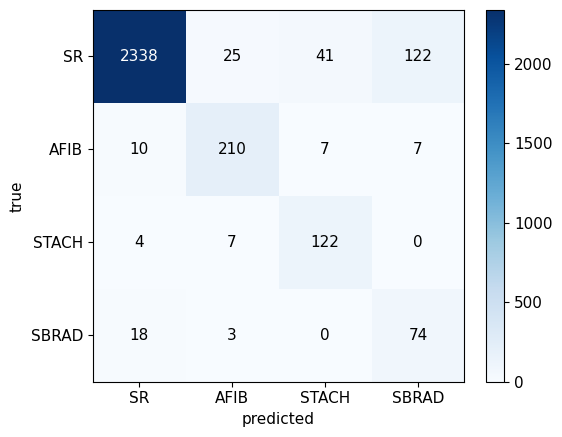

recall SR    0.9255740300870943
recall AFIB  0.8974358974358975
recall STACH 0.9172932330827067
recall SBRAD 0.7789473684210526


In [10]:
cm = confusion_matrix(yt, pt, labels=np.arange(N_CLASSES))
cm_df = pd.DataFrame(cm, index=CLASS_ORDER, columns=CLASS_ORDER)
cm_df.index.name = "true"
cm_df.columns.name = "pred"
display(cm_df)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(N_CLASSES), CLASS_ORDER)
ax.set_yticks(range(N_CLASSES), CLASS_ORDER)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

print("recall SR   ", metrics["per_class"]["SR"]["recall"])
print("recall AFIB ", metrics["per_class"]["AFIB"]["recall"])
print("recall STACH", metrics["per_class"]["STACH"]["recall"])
print("recall SBRAD", metrics["per_class"]["SBRAD"]["recall"])


**Observation:** AFIB recall (0.90) is close to SR (0.93). The weak class is SBRAD: recall 0.78 but precision 0.36, mostly from 122 SR records predicted as SBRAD.


## 11. Baseline summary


In [11]:
summary = pd.DataFrame({
    "Metric": [
        "Accuracy", "Macro-F1", "Weighted-F1", "PR-AUC (macro)",
        "AFIB Recall", "STACH Recall", "SBRAD Recall",
        "AFIB F1", "STACH F1", "SBRAD F1",
        "Val Macro-F1 (best)", "Best epoch",
    ],
    "Real-only CNN-LSTM": [
        metrics["accuracy"],
        metrics["macro_f1"],
        metrics["weighted_f1"],
        metrics["pr_auc_macro"],
        metrics["per_class"]["AFIB"]["recall"],
        metrics["per_class"]["STACH"]["recall"],
        metrics["per_class"]["SBRAD"]["recall"],
        metrics["per_class"]["AFIB"]["f1"],
        metrics["per_class"]["STACH"]["f1"],
        metrics["per_class"]["SBRAD"]["f1"],
        best["val_macro_f1"],
        best["epoch"],
    ],
})
out = summary.copy()
out["Real-only CNN-LSTM"] = [
    f"{v:.0f}" if name == "Best epoch" else f"{v:.4f}"
    for name, v in zip(summary["Metric"], summary["Real-only CNN-LSTM"])
]
display(out)


,Metric,Real-only CNN-LSTM
0,Accuracy,0.9183
1,Macro-F1,0.7835
2,Weighted-F1,0.9277
3,PR-AUC (macro),0.9003
4,AFIB Recall,0.8974
5,STACH Recall,0.9173
6,SBRAD Recall,0.7789
7,AFIB F1,0.8768
8,STACH F1,0.8053
9,SBRAD F1,0.4966


## 12. Save baseline


In [12]:
with open(BASELINE_DIR / "config.json", "w", encoding="utf-8") as f:
    json.dump({
        "dataset": "PTB-XL",
        "classes": CLASS_ORDER,
        "input_shape": [1000, 12],
        "split": "patient-level 70/15/15",
        "n_train": int(len(y_train)),
        "n_val": int(len(y_val)),
        "n_test": int(len(y_test)),
        "architecture": {
            "conv1": "Conv1d(12->32, k=7) + BN + ReLU + MaxPool(4)",
            "conv2": "Conv1d(32->64, k=5) + BN + ReLU + MaxPool(4)",
            "lstm": "LSTM(64, hidden=64, layers=1, unidirectional)",
            "head": "Dropout(0.3) + Linear(64->4)",
            "n_params": count_params(CNNLSTM()),
        },
        "train": TRAIN_CFG,
        "class_weights": {CLASS_ORDER[i]: float(class_weights_np[i]) for i in range(N_CLASSES)},
        "best_epoch": best["epoch"],
        "best_val_macro_f1": best["val_macro_f1"],
        "checkpoint": str(ckpt_path).replace("\\", "/"),
        "label_mapping": CLASS_TO_IDX,
    }, f, indent=2)

with open(BASELINE_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump({"val_macro_f1": best["val_macro_f1"], "best_epoch": best["epoch"], "test": metrics}, f, indent=2)

with open(BASELINE_DIR / "class_weights.json", "w", encoding="utf-8") as f:
    json.dump({CLASS_ORDER[i]: float(class_weights_np[i]) for i in range(N_CLASSES)}, f, indent=2)

with open(BASELINE_DIR / "label_mapping.json", "w", encoding="utf-8") as f:
    json.dump(label_info, f, indent=2)

with open(BASELINE_DIR / "history.json", "w", encoding="utf-8") as f:
    json.dump(history, f, indent=2)

cm_df.to_csv(BASELINE_DIR / "confusion_matrix.csv")

print("wrote")
for p in sorted(BASELINE_DIR.iterdir()):
    print(f"  {p.name:24s} {p.stat().st_size / 1024:7.1f} KB")


wrote
  class_weights.json           0.1 KB
  cnn_lstm_baseline.pt       190.7 KB
  config.json                  1.3 KB
  confusion_matrix.csv         0.1 KB
  history.json                 3.8 KB
  label_mapping.json           0.3 KB
  metrics.json                 1.1 KB


## Seed check

Retrain from scratch with the same seed and compare the selected validation Macro-F1.


In [13]:
model2, history2, best2 = run_training(SEED, verbose=False)
print("run 1  epoch", best["epoch"], "val Macro-F1", round(best["val_macro_f1"], 4))
print("run 2  epoch", best2["epoch"], "val Macro-F1", round(best2["val_macro_f1"], 4))
delta = abs(best["val_macro_f1"] - best2["val_macro_f1"])
print("abs delta", round(delta, 4))
print("same best epoch:", best["epoch"] == best2["epoch"])
# CPU LSTM is not fully deterministic; flag large drift only
print("within 0.02:", delta < 0.02)


run 1  epoch 12 val Macro-F1 0.7816
run 2  epoch 12 val Macro-F1 0.7816
abs delta 0.0
same best epoch: True
within 0.02: True


**Observation:** Same seed, same best epoch (12) and same val Macro-F1 (0.7816) on a second full retrain.


## 13. Baseline configuration — frozen

| Item | Value |
|---|---|
| Dataset | PTB-XL |
| Classes | SR / AFIB / STACH / SBRAD |
| Input | 1000 × 12 |
| Split | Patient-level 70/15/15 (13,811 / 2,960 / 2,988) |
| Model | CNN-LSTM, 46,756 params |
| Conv | Conv1d 12→32 k=7, Conv1d 32→64 k=5, each BN+ReLU+MaxPool(4) |
| LSTM | unidirectional, hidden 64, 1 layer |
| Loss | Class-weighted cross-entropy (train-only balanced weights) |
| Primary metric | Macro-F1 |
| Secondary metrics | Per-class recall / F1, PR-AUC, accuracy, confusion matrix |
| Optimizer | Adam, lr=1e-3, weight decay=1e-4, batch 64 |
| Schedule | max 25 epochs, ReduceLROnPlateau, early stop patience 7 |
| Random seed | 42 |
| Best checkpoint | epoch 12, val Macro-F1 0.782 |
| Test (once, after selection) | acc 0.918, Macro-F1 0.783, PR-AUC 0.900 |
| Path | `baseline/cnn_lstm_baseline.pt` |

Do not change this baseline later just to improve synthetic-data results. If a change is necessary, create Baseline V2 and document why.


## Why this baseline matters

Before introducing synthetic ECG data, we need to establish how well the classifier performs using only real ECG data. This is the reference point for later comparisons against random synthetic augmentation and quality-selected synthetic augmentation.

```
REAL ONLY
   ↓
CNN-LSTM
   ↓
REAL TEST
   ↓
BASELINE   ← freeze here

Later:
REAL + RANDOM SYNTHETIC          REAL + QUALITY-SELECTED SYNTHETIC
   ↓                                ↓
CNN-LSTM                         CNN-LSTM
   ↓                                ↓
REAL TEST                        REAL TEST
```

Keep the CNN-LSTM and evaluation setup comparable across those experiments. Architecture, seed, class-weight rule, and test set stay fixed unless a V2 baseline is explicitly declared.
